[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/progManu/mdmc_dl_hands_on/blob/master/solutions/solved_hands_on_2a_representations.ipynb)

# Lab 2a: Learning representations without labels (solutions)

## Before you start

This notebook uses files from the course repository (the figures in `notebooks_imgs/`), so clone the whole repository and open the notebook from inside it.

Locally:

```bash
git clone <REPO_URL> mdmc_dl_hands_on
cd mdmc_dl_hands_on
jupyter lab
```

On Colab, run this in a code cell first:

```python
!git clone <REPO_URL> mdmc_dl_hands_on
%cd mdmc_dl_hands_on
```

This is the solved version: every exercise is completed, and the homework solutions are at the end. Run the cells in order. Your numbers may differ slightly from the ones in the text because of random initialisation.

## What this lab is about

In Lab 1 we gave the network images *and* labels and trained it to predict the label. On the way, the hidden layers turned every image into a vector of numbers from which the label was easy to read. That vector is a **representation** of the image, and it is the most valuable thing a neural network learns.

Today we ask two questions:

1. Can we learn a good representation **without labels**?
2. How do we know whether a representation is good?

A representation is just a map $x \mapsto z$ from the 784 pixels of an image to a vector $z$, usually much shorter. The raw pixels are a representation too, just not a very convenient one: two images of the same digit written slightly differently can be far apart pixel by pixel.

For the second question we take a practical view: **a good representation makes many different tasks easy, including tasks it was not built for.** So the plan is:

- **Part 1.** Build a compressed representation with **PCA**, the linear method you already know.
- **Part 2.** Learn a non-linear one with an **autoencoder**, a network trained to rebuild its own input, and compare it with PCA.
- **Part 3.** Freeze the representations and use them, with the raw pixels as a baseline, for three tasks:
  - **clustering**: group the images without labels;
  - **anomaly detection**: recognise inputs that are not digits;
  - **classification with few labels**: train a classifier with 1, 10 or 100 labelled images per digit.

MNIST does have labels, but we keep them hidden while building the representations. We use them only to evaluate the results and to colour plots, and in the last task, where a few of them are allowed.

Keep one question in mind for the whole lab: **what does a good representation buy us?** Part 3 answers it: once the images are turned into good codes, very simple tools (K-means, a reconstruction error, a linear classifier) solve tasks that are much harder on the raw pixels, including tasks the representation was never trained for.

# Setup

Nothing new in this section: imports, the data and a few plotting helpers. Read it quickly and move on.

In [29]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.neighbors import NearestNeighbors
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision.datasets import MNIST, FashionMNIST
from torchvision.transforms import v2

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("Using device:", DEVICE)

_ = torch.manual_seed(0)

Using device: cuda


## Data

Same MNIST and the same 48k / 12k train / validation split as in Lab 1, with one difference: we do **not** normalise the images, we only scale the pixels to $[0, 1]$. The autoencoder has to output images, and it is simpler to compare input and output (and to plot them) if both are plain images with 0 = black and 1 = white.

The whole dataset fits in memory, so we load it once into arrays of shape `(n_images, 784)`, one row per image. scikit-learn (PCA, K-means, ...) wants exactly this format, and for PyTorch we wrap the same arrays in a `TensorDataset`. This also makes training much faster than applying the transforms to every image at every epoch.

In [30]:
transforms = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
mnist_train = MNIST("datasets", train=True, download=True, transform=transforms)
mnist_test = MNIST("datasets", train=False, download=True, transform=transforms)
mnist_train, mnist_val = random_split(mnist_train, [48000, 12000], generator=torch.Generator().manual_seed(0))


def to_arrays(dataset):
    # All the images of `dataset` as a (n, 784) array and the labels as a (n,) array.
    X, y = zip(*DataLoader(dataset, batch_size=1000))
    return torch.cat(X).reshape(-1, 784).numpy(), torch.cat(y).numpy()


X_train, y_train = to_arrays(mnist_train)
X_val, y_val = to_arrays(mnist_val)
X_test, y_test = to_arrays(mnist_test)
print("train:", X_train.shape, " val:", X_val.shape, " test:", X_test.shape)

BATCH_SIZE = 128


def make_loader(X, y, batch_size=BATCH_SIZE, shuffle=False):
    # DataLoader over in-memory arrays; images are reshaped back to (1, 28, 28).
    dataset = TensorDataset(torch.as_tensor(X).reshape(-1, 1, 28, 28), torch.as_tensor(y))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)

train: (48000, 784)  val: (12000, 784)  test: (10000, 784)


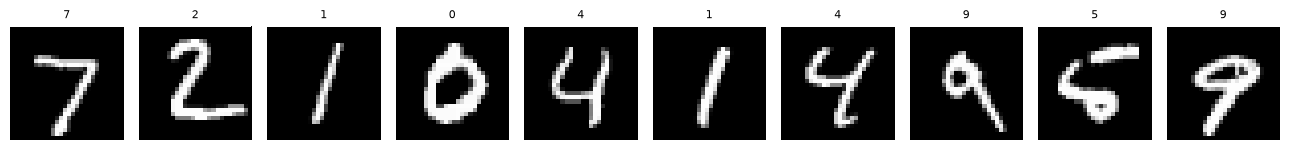

In [31]:
def plot_images(images, titles=None, n_cols=10, suptitle=None, size=1.3):
    # Plot images of shape (n, 784) or (n, 1, 28, 28) in a grid, gray scale in [0, 1].
    images = torch.as_tensor(np.asarray(images)).reshape(-1, 28, 28)
    n_rows = -(-len(images) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * n_rows + 0.4), squeeze=False)
    for ax in axes.flat:
        ax.set_axis_off()
    for i, (ax, img) in enumerate(zip(axes.flat, images)):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        if titles is not None:
            ax.set_title(titles[i], fontsize=8)
    if suptitle is not None:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


def plot_latent_space(z, y, title, ax=None):
    # Scatter plot of 2D codes, one point per image, coloured by the (hidden) label.
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 6))
    sc = ax.scatter(z[:, 0], z[:, 1], c=y, cmap="tab10", s=2, alpha=0.7, vmin=-0.5, vmax=9.5)
    plt.colorbar(sc, ax=ax, ticks=range(10)).set_label("digit (only for the colours)")
    ax.set_title(title)
    ax.set_xlabel("$z_1$")
    ax.set_ylabel("$z_2$")
    if show:
        plt.show()


def plot_curves(curves, title, ylabel, reference=None):
    # Same as Lab 1: one line per list of values (one value per epoch).
    fig, ax = plt.subplots(figsize=(6, 4))
    for label, values in curves.items():
        ax.plot(range(1, len(values) + 1), values, marker="o", label=label)
    if reference is not None:
        ax.axhline(reference[1], color="gray", linestyle="--", label=reference[0])
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()


plot_images(X_test[:10], titles=list(y_test[:10]))

# Part 1: PCA, a linear representation

A quick recap. PCA finds the directions of the 784-dimensional pixel space along which the images vary the most, the **principal components** $w_1, \dots, w_k$ (each one is a vector of 784 numbers, so it can be drawn as an image). It gives us both an encoder and a decoder:

- **encode**: an image becomes $k$ numbers, its coordinates along the components, $z_i = w_i^\top (x - \bar{x})$;
- **decode**: the image is approximated as the mean image plus a mix of components, $\hat{x} = \bar{x} + \sum_i z_i w_i$.

Among all linear encoder/decoder pairs with $k$ numbers, PCA is the one with the smallest **reconstruction error** $\|x - \hat{x}\|^2$. Keep these three words in mind (encoder, decoder, reconstruction error): the autoencoder uses exactly the same ones.

| scikit-learn | what it does | shapes |
|---|---|---|
| `PCA(n_components=k).fit(X)` | computes the mean image and the $k$ components | `X`: `(n, 784)` |
| `pca.transform(X)` | encode, $x \to z$ | `(n, 784)` → `(n, k)` |
| `pca.inverse_transform(Z)` | decode, $z \to \hat{x}$ | `(n, k)` → `(n, 784)` |

`fit` only receives the images: no labels.

### Exercise 1: MNIST in two numbers

Fit a PCA with 2 components on `X_train` and encode the test images with it. `plot_latent_space` draws one point per test image.

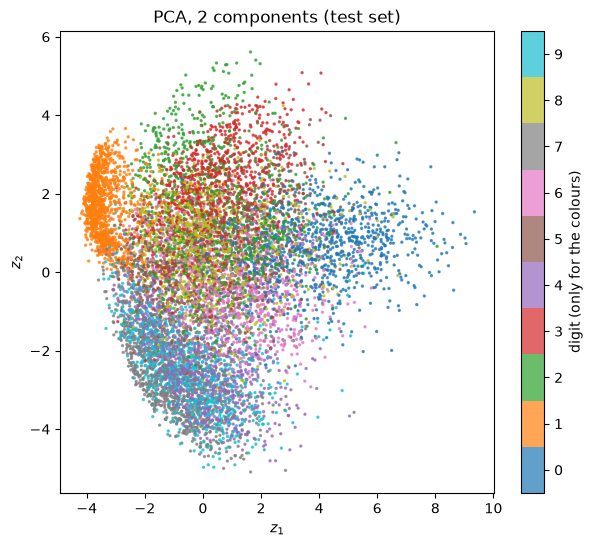

In [32]:
pca_2 = PCA(n_components=2).fit(X_train)                    # PCA with n_components=2, fitted on X_train
pca_2_z = pca_2.transform(X_test)                    # encode X_test: (10000, 784) -> (10000, 2)

plot_latent_space(pca_2_z, y_test, title="PCA, 2 components (test set)")

The 0s and 1s are already separated (a 1 has few white pixels, a 0 many), but most digits overlap in the middle. Two linear directions are not enough to tell ten digits apart.

How many components do we need to keep most of the information? Each component explains a fraction of the total variance (`explained_variance_ratio_`).

Fit a PCA that keeps **all** the components on `X_train`: `PCA()` without `n_components` keeps all 784 of them. The cell then plots the cumulative explained variance, the mean image and the first components.

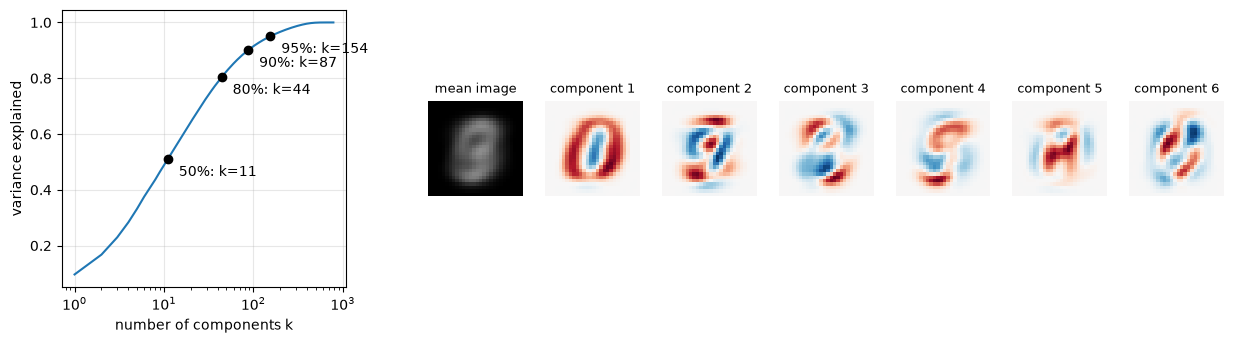

In [33]:
pca_full = PCA().fit(X_train)                 # PCA keeping all the components (no n_components), fitted on X_train
cumulative = np.cumsum(pca_full.explained_variance_ratio_)   # cumulative histogram of the explained_variance_ratio_

# plotting the CDF of explained_variance_ratio_
fig = plt.figure(figsize=(15, 3.6))
gs = fig.add_gridspec(1, 9, width_ratios=[3, 0.4, 1, 1, 1, 1, 1, 1, 1])
ax = fig.add_subplot(gs[0, 0])
ax.plot(range(1, 785), cumulative)
for target in [0.5, 0.8, 0.9, 0.95]:
    k = int(np.searchsorted(cumulative, target)) + 1
    ax.plot(k, cumulative[k - 1], "o", color="black")
    ax.annotate(f"{target:.0%}: k={k}", (k, cumulative[k - 1]), xytext=(8, -12), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("number of components k")
ax.set_ylabel("variance explained")
ax.grid(alpha=0.3)

# plotting the components of PCA for the decode function.
# the mean image and the first components drawn as images (red = positive, blue = negative)
for i in range(7):
    ax = fig.add_subplot(gs[0, i + 2])
    if i == 0:
        ax.imshow(pca_full.mean_.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_title("mean image", fontsize=9)
    else:
        c = pca_full.components_[i - 1].reshape(28, 28)
        ax.imshow(c, cmap="RdBu_r", vmin=-abs(c).max(), vmax=abs(c).max())
        ax.set_title(f"component {i}", fontsize=9)
    ax.set_axis_off()
plt.show()

About 90% of the variance is kept with fewer than 100 of the 784 components: MNIST is very compressible. The components themselves are smooth blobs that look like pieces of digits.

### Exercise 2: reconstruction error

1. Complete `mse_per_image`: for two arrays of shape `(n, 784)`, return the mean squared error over the pixels of each image, an array of shape `(n,)`. Square the differences and average along `axis=1` (the pixels), not over the images. The check cell below tests it.
2. For each `k`, fit a `PCA(n_components=k)` on `X_train`, then encode the test images with `transform` and decode the codes with `inverse_transform` (see the table above) to get the reconstructions `X_rec`, shape `(10000, 784)`.

Expected: the error goes from about 0.056 with 2 components to about 0.003 with 150.

k =   2   test MSE: 0.0557
k =  10   test MSE: 0.0341
k =  50   test MSE: 0.0115
k = 150   test MSE: 0.0034


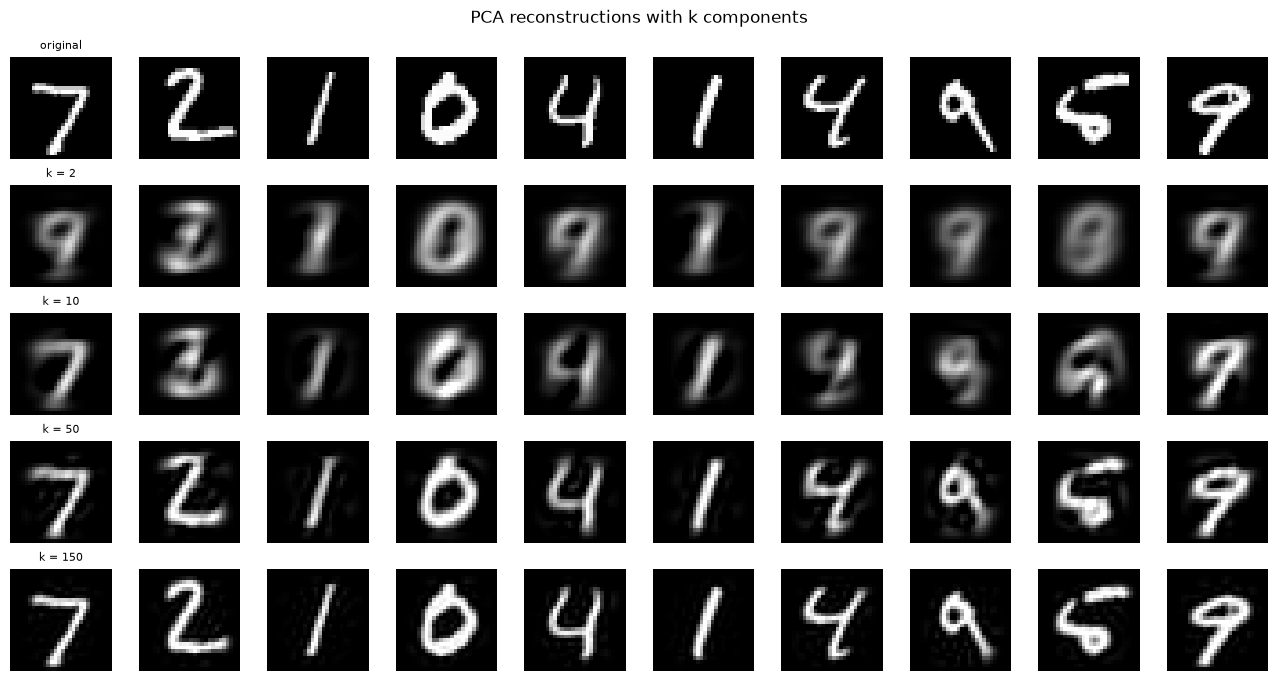

In [34]:
def mse_per_image(X, X_rec):
    # Mean squared error per pixel of every image: (n, 784), (n, 784) -> (n,)
    # X and X_rec are np.arrays
    
    return ((X - X_rec) ** 2).mean(axis=1)          # square the differences, average over the pixels


examples = X_test[:10]
rows, titles = [examples], ["original"] + [""] * 9
for k in [2, 10, 50, 150]:
    pca_k = PCA(n_components=k).fit(X_train)        # PCA with k components, fitted on X_train
    X_rec = pca_k.inverse_transform(pca_k.transform(X_test))   # encode X_test, then decode it: (10000, 784)
    
    print(f"k = {k:>3}   test MSE: {mse_per_image(X_test, X_rec).mean():.4f}")
    rows.append(np.clip(X_rec[:10], 0, 1))
    titles += [f"k = {k}"] + [""] * 9

plot_images(np.concatenate(rows), titles=titles, suptitle="PCA reconstructions with k components")

In [35]:
# Check
assert np.allclose(mse_per_image(np.zeros((3, 784)), np.full((3, 784), 0.5)), 0.25)
print("All good!")

All good!


PCA gives a perfectly reasonable representation and needs no training. Its limit is that it is **linear**: every image is rebuilt as the mean plus a weighted sum of the same fixed images. With few components that is not enough, as the blurry blobs for $k = 2$ and $k = 10$ show.

Can a non-linear encoder do better with the same number of values?

# Part 2: Learning a representation with an autoencoder

An **autoencoder** (AE) keeps the structure of PCA, an encoder followed by a decoder, but both are neural networks:

- the **encoder** $f_\phi$ maps the image to a short **code** (or latent vector) $z = f_\phi(x)$;
- the **decoder** $g_\theta$ rebuilds the image from the code, $\hat{x} = g_\theta(z)$.

<p align="center">
  <img src="../notebooks_imgs/aes.png" alt="autoencoder" width="500" style="background-color: white;"/>
</p>

The network is trained to output its own input, $\hat{x} \approx x$. This would be trivial if the code were large, but the middle layer (the **bottleneck**) has only a few units, 2 or 10 today. To rebuild the images through it, the encoder has to keep only what matters and the decoder has to learn what digits look like.

The target is the input itself, so **no labels are needed**. Tasks where the target is built from the data like this are called **self-supervised**; the same idea, at a much larger scale, is how modern foundation models are pre-trained.

| | layers | output |
|---|---|---|
| encoder | `Linear(784, 512)`, ReLU, `Linear(512, 256)`, ReLU, `Linear(256, latent_dim)` | `(batch, latent_dim)` |
| decoder | `Linear(latent_dim, 256)`, ReLU, `Linear(256, 512)`, ReLU, `Linear(512, 784)`, Sigmoid | `(batch, 784)` → `(batch, 1, 28, 28)` |

The code has no activation (it can be any real number); the sigmoid at the end of the decoder keeps the output pixels in $(0, 1)$, like the input.

Instead of calling the layers one by one in `forward` as in Lab 1, we group them with `torch.nn.Sequential`, which applies its layers in order. This keeps the encoder and the decoder as two separate modules that we can use on their own later.

### Exercise 3: the autoencoder

Complete the `AutoEncoder` following the table above.

- `__init__`: fill the two `torch.nn.Sequential` with the layers of the table, in order. You need `torch.nn.Linear(in_features, out_features)`, `torch.nn.ReLU()` and `torch.nn.Sigmoid()`; the size of the code is `latent_dim`.
- `encode(x)`: `x` is a batch of images of shape `(batch, 1, 28, 28)`. Flatten it to `(batch, 784)` with `x.reshape(x.shape[0], -1)`, as in the Lab 1 MLP, and pass it through `self.encoder`.
- `decode(z)`: pass the codes through `self.decoder`, then reshape the output from `(batch, 784)` back to images with `.reshape(-1, 1, 28, 28)`.

`forward` is given: it is just `decode(encode(x))`. The last lines of the cell check the shapes on a random batch.

In [36]:
class AutoEncoder(torch.nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = torch.nn.Sequential(
            torch.nn.Linear(784, 512),          # Linear: 784 -> 512
            torch.nn.ReLU(),                    # ReLU
            torch.nn.Linear(512, 256),          # Linear: 512 -> 256
            torch.nn.ReLU(),                    # ReLU
            torch.nn.Linear(256, latent_dim),   # Linear: 256 -> latent_dim (no activation: the code can be any real number)
        )
        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(latent_dim, 256),   # Linear: latent_dim -> 256
            torch.nn.ReLU(),                    # ReLU
            torch.nn.Linear(256, 512),          # Linear: 256 -> 512
            torch.nn.ReLU(),                    # ReLU
            torch.nn.Linear(512, 784),          # Linear: 512 -> 784
            torch.nn.Sigmoid(),                 # Sigmoid: output pixels in (0, 1)
        )

    def encode(self, x):
        # (batch, 1, 28, 28) -> flatten -> (batch, 784) -> encoder -> (batch, latent_dim)
        return self.encoder(x.reshape(x.shape[0], -1))

    def decode(self, z):
        # (batch, latent_dim) -> decoder -> (batch, 784) -> reshape -> (batch, 1, 28, 28)
        return self.decoder(z).reshape(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))


ae_2 = AutoEncoder(latent_dim=2).to(DEVICE)
x = torch.rand(BATCH_SIZE, 1, 28, 28, device=DEVICE)
print("code:  ", ae_2.encode(x).shape)   # expected (128, 2)
print("output:", ae_2(x).shape)          # expected (128, 1, 28, 28)

code:   torch.Size([128, 2])
output: torch.Size([128, 1, 28, 28])


### Exercise 4: training without labels

The loss is the same reconstruction error we used for PCA, the MSE over the pixels (`F.mse_loss`), so the comparison between the two is fair. In Lab 1 the loss compared the output with the label $y$; here it compares the output with the input $x$. That is the only real change in the training loop.

Complete the three functions, starting from `train_one_epoch`, `evaluate` and `fit` of Lab 1:

- `train_one_epoch_unsupervised`: the loop is `for x, _ in dataloader` (the labels are ignored). Compute the loss `F.mse_loss(model(x), x)`, then do the three optimizer steps of Lab 1, in the same order: reset the gradients, backward pass, update the weights.
- `evaluate_unsupervised`: the same loss, without gradients, averaged over the whole dataset. `F.mse_loss` returns the mean over the batch, so multiply it by the number of images in the batch, `len(x)`, before summing (as in Lab 1, the last batch can be smaller).
- `train_autoencoder`: create an Adam optimizer, `torch.optim.Adam(model.parameters(), lr=1e-3)`; then at every epoch train for one epoch on `train_loader` and compute the loss on `val_loader` (both loaders are defined in the Setup).

The next cell uses them to train the AE.

In [37]:
def train_one_epoch_unsupervised(model, dataloader, optimizer):
    model.train()
    epoch_loss = 0
    for x, _ in dataloader:            # labels are not used
        x = x.to(DEVICE)
        loss = F.mse_loss(model(x), x)  # reconstruction error: the target is the input itself
        optimizer.zero_grad()          # reset the gradients
        loss.backward()                # backward pass: compute the gradients
        optimizer.step()               # update the weights
        epoch_loss += loss.item()
    return epoch_loss / len(dataloader)


def evaluate_unsupervised(model, dataloader):
    model.eval()
    total = 0
    with torch.no_grad():
        for x, _ in dataloader:
            x = x.to(DEVICE)
            total += F.mse_loss(model(x), x).item() * len(x)   # mean loss of the batch (a Python float) times the batch size
    return total / len(dataloader.dataset)


def train_autoencoder(model, epochs=10, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)   # Adam on the parameters of the model, lr=1e-3
    train_losses, val_losses = [], []
    for epoch in range(epochs):
        train_loss = train_one_epoch_unsupervised(model, train_loader, optimizer)   # one epoch of training on train_loader
        train_losses.append(train_loss)
        val_loss = evaluate_unsupervised(model, val_loader)   # average loss on val_loader
        val_losses.append(val_loss)
        if verbose:
            print(f"epoch {epoch + 1:>2}/{epochs}   train {train_losses[-1]:.4f}   val {val_losses[-1]:.4f}")
    return train_losses, val_losses

Now train the AE with a **2-number bottleneck** and compare it with **PCA with 2 components**. Expected test MSE: about 0.038 for the AE against 0.056 for PCA.

epoch  1/10   train 0.0583   val 0.0487
epoch  2/10   train 0.0461   val 0.0440
epoch  3/10   train 0.0428   val 0.0418
epoch  4/10   train 0.0410   val 0.0404
epoch  5/10   train 0.0398   val 0.0395
epoch  6/10   train 0.0390   val 0.0388
epoch  7/10   train 0.0384   val 0.0386
epoch  8/10   train 0.0379   val 0.0379
epoch  9/10   train 0.0376   val 0.0378
epoch 10/10   train 0.0373   val 0.0374

test MSE   AE: 0.0374   PCA: 0.0557


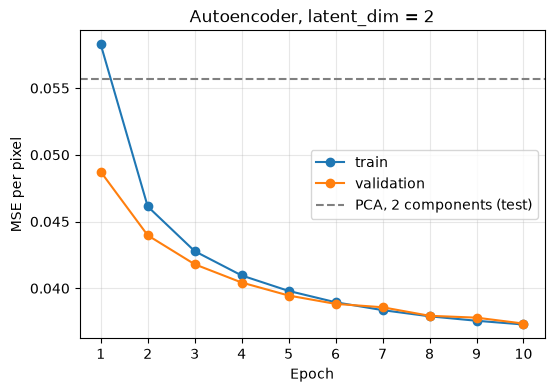

In [38]:
ae_2_train, ae_2_val = train_autoencoder(ae_2, epochs=10)

# test error evaluation
ae_2_mse = evaluate_unsupervised(ae_2, test_loader)      # evaluate autoncoder per pixel error on test
pca_2_mse = mse_per_image(X_test, pca_2.inverse_transform(pca_2_z)).mean()      # evaluate pca per pixel error
print(f"\ntest MSE   AE: {ae_2_mse:.4f}   PCA: {pca_2_mse:.4f}")

plot_curves({"train": ae_2_train, "validation": ae_2_val}, title="Autoencoder, latent_dim = 2",
            ylabel="MSE per pixel", reference=("PCA, 2 components (test)", pca_2_mse))

### Exercise 5: reconstructions and codes

Two small helpers that we will use a lot from now on. Both take a NumPy array `(n, 784)` and return a NumPy array:

- `ae_reconstruct(model, X)`: the reconstructions, shape `(n, 784)`. It is given: read it, it shows the round trip NumPy → tensor on `DEVICE` → model → back to the CPU → NumPy.
- `get_codes(model, X)`: the codes, shape `(n, latent_dim)`. Same round trip as `ae_reconstruct`, but through the encoder only: call `model.encode` on `torch.as_tensor(X).to(DEVICE)`. (`encode` flattens its input, so it accepts `(n, 784)` as well as `(n, 1, 28, 28)`.)

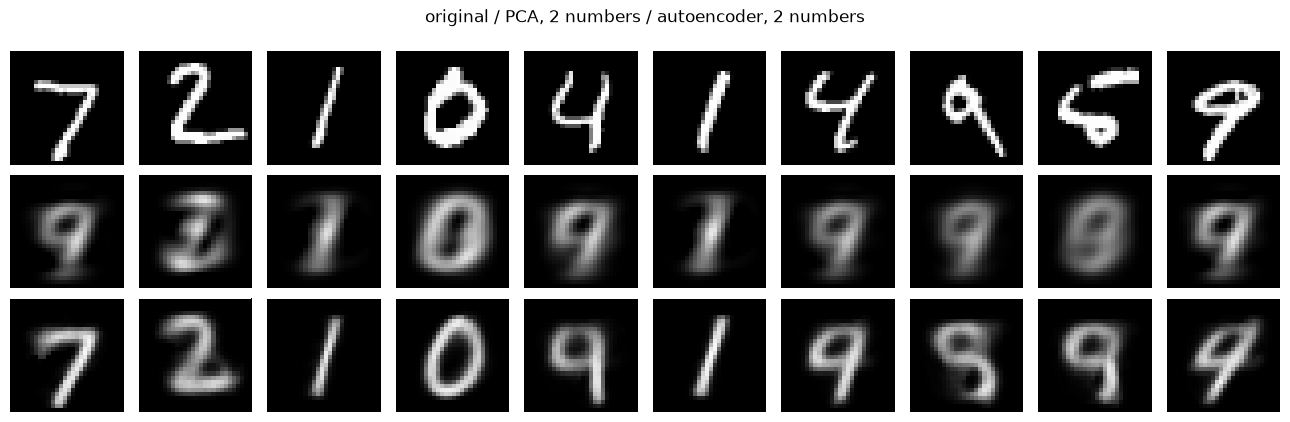

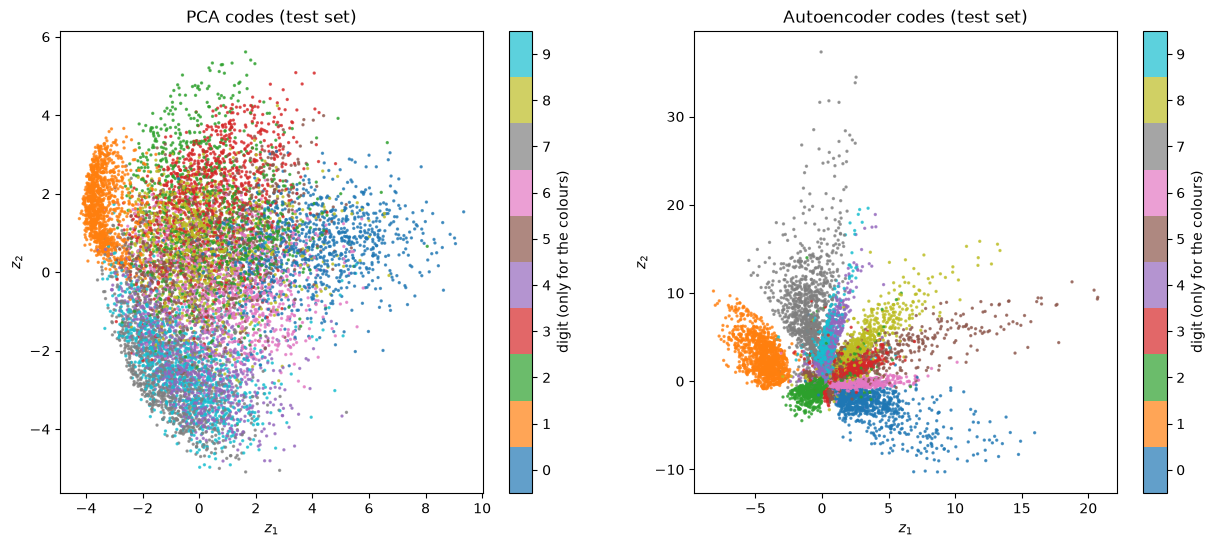

In [39]:
def ae_reconstruct(model, X):
    # NumPy (n, 784) -> tensor on DEVICE -> whole AE -> back to the CPU -> NumPy (n, 784)
    model.eval()
    with torch.no_grad():
        return model(torch.as_tensor(X).to(DEVICE)).cpu().reshape(len(X), -1).numpy()


def get_codes(model, X):
    # NumPy (n, 784) -> tensor on DEVICE -> encoder only -> back to the CPU -> NumPy (n, latent_dim)
    model.eval()
    with torch.no_grad():
        return model.encode(torch.as_tensor(X).to(DEVICE)).cpu().numpy()


plot_images(np.concatenate([examples,
                            np.clip(pca_2.inverse_transform(pca_2.transform(examples)), 0, 1),
                            ae_reconstruct(ae_2, examples)]),
            suptitle="original / PCA, 2 numbers / autoencoder, 2 numbers")

ae_2_z = get_codes(ae_2, X_test)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_latent_space(pca_2_z, y_test, title="PCA codes (test set)", ax=axes[0])
plot_latent_space(ae_2_z, y_test, title="Autoencoder codes (test set)", ax=axes[1])
plt.show()

With the same two numbers, the AE rebuilds recognisable digits where PCA gives blobs. The latent space is even more telling: without ever seeing a label, the AE has placed images of the same digit next to each other, because grouping them is the most efficient way to rebuild them. The digits that still overlap (4 and 9; 3, 5 and 8) are the ones the Lab 1 classifier confused most.

This is our first hint that the AE learned a better representation, not just a better compressor.

### Exercise 6: a larger bottleneck

Two numbers are handy for plotting but too few to describe a digit. For the rest of the lab we use codes of **10 numbers**, for both the AE and PCA. (The fact that there are also 10 digits is a coincidence; the homework explores other sizes.)

epoch  1/10   train 0.0455   val 0.0250
epoch  2/10   train 0.0221   val 0.0199
epoch  3/10   train 0.0189   val 0.0182
epoch  4/10   train 0.0174   val 0.0172
epoch  5/10   train 0.0163   val 0.0161
epoch  6/10   train 0.0156   val 0.0155
epoch  7/10   train 0.0150   val 0.0152
epoch  8/10   train 0.0145   val 0.0147
epoch  9/10   train 0.0140   val 0.0143
epoch 10/10   train 0.0137   val 0.0141

test MSE with 10 numbers   AE: 0.0138   PCA: 0.0341


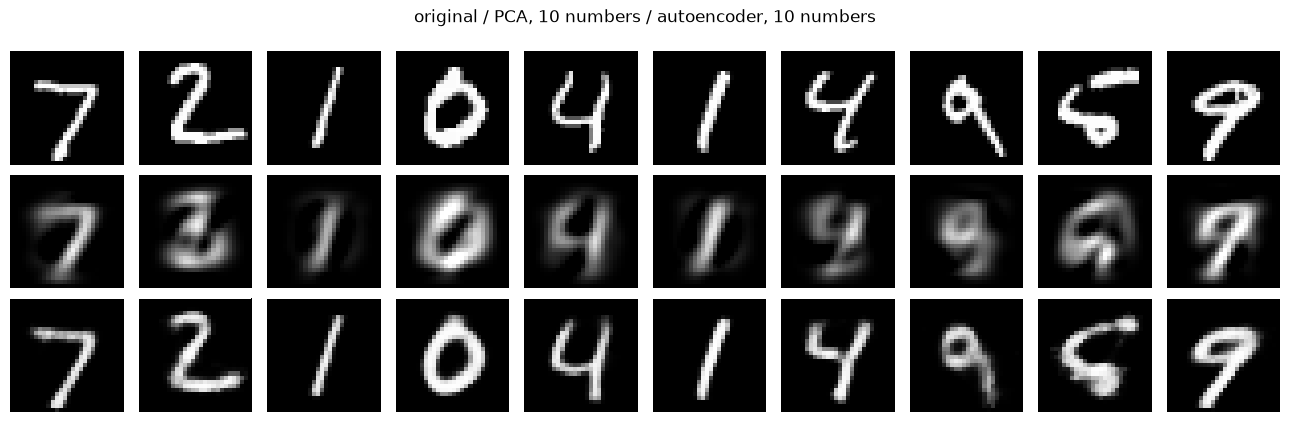

In [40]:
LATENT_DIM = 10

torch.manual_seed(0)
ae = AutoEncoder(latent_dim=LATENT_DIM).to(DEVICE)                     # define AutoEncoder with latent_dimension 10
ae_train, ae_val = train_autoencoder(ae, epochs=10)                     # train the autoencoder for 10 epochs
pca = PCA(n_components=LATENT_DIM).fit(X_train)                         # fit PCA with with latent_dimension 10

ae_mse = evaluate_unsupervised(ae, test_loader)                         # evaluate autoencoder with latent dim 10 on test data
pca_mse = mse_per_image(X_test, pca.inverse_transform(pca.transform(X_test))).mean()   # evaluate PCA with 10 componets in test

print(f"\ntest MSE with {LATENT_DIM} numbers   AE: {ae_mse:.4f}   PCA: {pca_mse:.4f}")

plot_images(np.concatenate([examples,
                            np.clip(pca.inverse_transform(pca.transform(examples)), 0, 1),
                            ae_reconstruct(ae, examples)]),
            suptitle=f"original / PCA, {LATENT_DIM} numbers / autoencoder, {LATENT_DIM} numbers")

With 10 numbers the AE error is less than half that of PCA, and the reconstructions are close to the originals.

But reconstruction is not what we care about: we already have the images. What we want to know is whether the **codes** are useful. That is the subject of the rest of the lab.

# Part 3: Putting the representations to work

From now on the AE and PCA are **frozen**: we only use them to turn images into vectors. We compare three representations of every image:

| representation | size | how it was obtained |
|---|---|---|
| raw pixels | 784 | nothing to learn |
| PCA codes | 10 | linear, fitted without labels |
| AE codes | 10 | non-linear, learned without labels |

On top of them we use deliberately simple tools (K-means, a reconstruction error, a linear classifier). The tools are the same for all three, so any difference in the results comes from the representation alone. None of the tasks below is the one the AE was trained for (rebuilding its input): if the AE codes still do better, it is because learning a representation, even without labels, has made these tasks easier.

In [41]:
reps = {
    "pixels": (X_train, X_test),
    "PCA": (pca.transform(X_train), pca.transform(X_test)),
    "AE": (get_codes(ae, X_train), get_codes(ae, X_test)),
}
results = {name: {} for name in reps}   # we collect every score here for the final summary

for name, (Z_train, Z_test) in reps.items():
    print(f"{name:<6} train {Z_train.shape}  test {Z_test.shape}")

pixels train (48000, 784)  test (10000, 784)
PCA    train (48000, 10)  test (10000, 10)
AE     train (48000, 10)  test (10000, 10)


## 3.1 Clustering

First, can we find the digits without labels? We run **K-means** with $K = 10$ on each representation. It relies entirely on Euclidean distances, so it is a direct test of the geometry of the representation: in a good one, images of the same digit are close to each other and far from the other digits.

*The clusters have arbitrary ids (cluster 3 is not digit 3). To score them, we name each cluster after its most common digit and compute the accuracy of this naming, the **clustering accuracy**. Random clusters would give about 0.1.*

### Exercise 7: clustering accuracy

1. Complete `cluster_accuracy(y_true, clusters)`. Both arguments have shape `(n,)`: the true digit and the cluster id of every image. For each cluster `k`:
   - select the true labels of the images in that cluster with a boolean mask, `y_true[clusters == k]`;
   - count how many images of each digit the cluster contains with `np.bincount(labels_k)`. It returns an array whose entry `d` is the number of times the value `d` appears in `labels_k`. For example, if a cluster contains images labelled `[7, 7, 1, 7, 9]`, then `np.bincount` gives `[0, 1, 0, 0, 0, 0, 0, 3, 0, 1]`: zero 0s, one 1, ..., three 7s, zero 8s, one 9;
   - the largest entry, `.max()`, is the number of images of the most common digit (3 in the example). If we name the cluster after that digit ("this is the cluster of the 7s"), these are exactly the images we name correctly: add this number to `correct`.

   *The `assert` right after the function checks it on a tiny example with 4 images: cluster 5 contains labels `[0, 0, 1]`, so it is named "0" and 2 images are right; cluster 7 contains `[1]`, so it is named "1" and 1 image is right. In total 3 out of 4, an accuracy of 0.75.*
   
2. For each representation, fit `KMeans(n_clusters=10, n_init=5, random_state=0)` on the training codes `Z_train`, then assign every test image to a cluster with `.predict(Z_test)`.

Expected: about 0.58 for pixels and PCA, about 0.70 for the AE.

In [42]:
def cluster_accuracy(y_true, clusters):
    correct = 0
    for k in np.unique(clusters):
        labels_k = y_true[clusters == k]   # true labels of the images assigned to cluster k
        correct += np.bincount(labels_k).max()   # count of the most common digit among labels_k
    return correct / len(y_true)


assert cluster_accuracy(np.array([0, 0, 1, 1]), np.array([5, 5, 5, 7])) == 0.75

clusters = {}
for name, (Z_train, Z_test) in reps.items():
    kmeans = KMeans(n_clusters=10, n_init=5, random_state=0).fit(Z_train)   # fit KMeans on Z_train
    clusters[name] = kmeans.predict(Z_test)   # cluster id of every test image, shape (10000,)
    results[name]["clustering acc."] = cluster_accuracy(y_test, clusters[name]) # compute accuracy on test
    print(f"{name:<6} clustering accuracy: {results[name]['clustering acc.']:.3f}")

pixels clustering accuracy: 0.585
PCA    clustering accuracy: 0.580
AE     clustering accuracy: 0.692


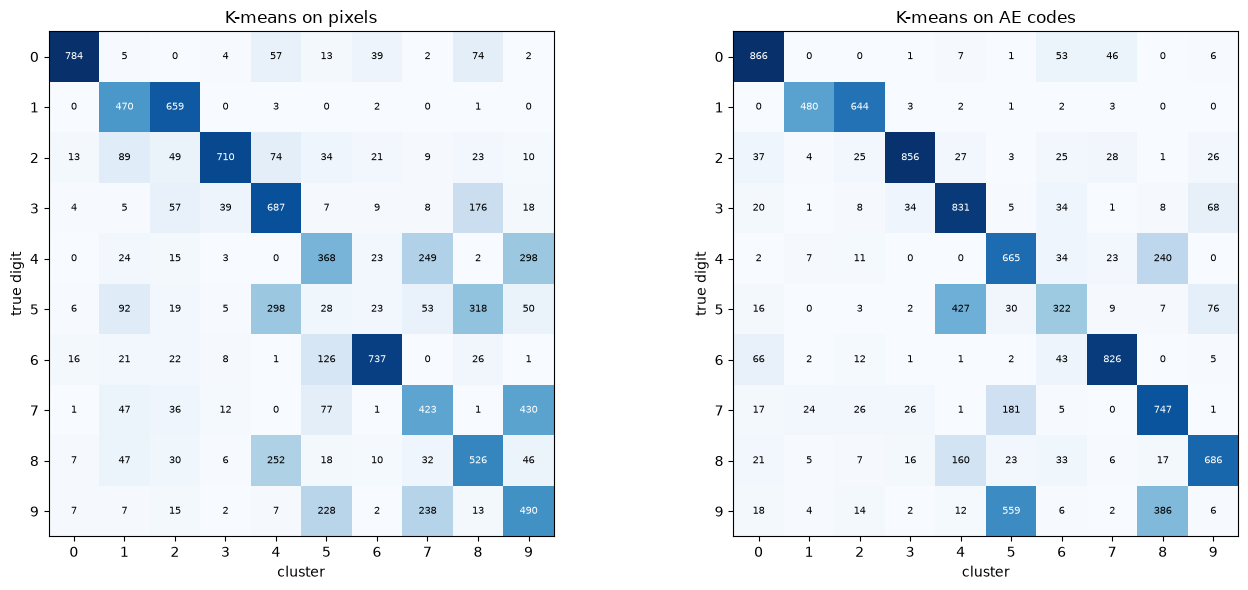

In [43]:
def plot_contingency(y_true, clusters, title, ax):
    # Rows: true digit, columns: cluster. Each cell counts the test images.
    cm = confusion_matrix(y_true, clusters)                     # (10 digits, 10 clusters)
    main_digit = cm.argmax(axis=0)                              # most common digit of every cluster
    cm = cm[:, np.argsort(main_digit, kind="stable")]           # reorder the clusters by their main digit
    ax.imshow(cm, cmap="Blues")
    for i in range(10):
        for k in range(10):
            ax.text(k, i, cm[i, k], ha="center", va="center", fontsize=7,
                    color="white" if cm[i, k] > cm.max() / 2 else "black")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xlabel("cluster")
    ax.set_ylabel("true digit")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_contingency(y_test, clusters["pixels"], "K-means on pixels", axes[0])
plot_contingency(y_test, clusters["AE"], "K-means on AE codes", axes[1])
plt.tight_layout()
plt.show()

A perfect clustering would show a single dark cell per row and per column. On pixels, 4, 7 and 9 share clusters, 3 and 5 are mixed, and to compensate other digits (often the 1s, straight and slanted) are split in two. On the AE codes 0, 2, 3, 6, 7 and 8 each get a clean cluster. What remains mixed is what we saw in the 2D latent space: 4 and 9 share a cluster and many 5s end up with the 3s. The 1s are still split in two.

Note that PCA does no better than the pixels here: it keeps most of the variance, but variance is not the same as "which digit is it".

## 3.2 Anomaly detection

A representation trained on digits encodes what digits look like. If we give it something else, the code cannot describe it and the decoder rebuilds a digit instead. So the **reconstruction error** is a natural anomaly score: low for inputs that resemble the training data, high for anything else. Note that we never show the model an anomaly.

This needs a decoder, so we compare PCA and the AE (raw pixels have nothing to reconstruct). As anomalies we use **FashionMNIST**, the dataset of the Lab 1 homework: same format, but clothes instead of digits.

The reconstruction error is a score, not a decision. To decide, we need a **threshold**: an image whose error is above it is flagged as an anomaly. We choose it without looking at any anomaly: we take the 95th percentile of the error on the MNIST **validation** images, so that only about 5% of the normal digits are flagged by mistake.

We then look at the decisions with a **confusion matrix**, as in Lab 1, but with two classes: the rows are the true class (MNIST = normal, FashionMNIST = anomaly), the columns the decision. The top-right cell counts the false alarms (digits flagged as anomalies), the bottom-left cell the missed anomalies (clothes accepted as digits). The two classes have the same size (10000 images each), so the **accuracy**, the fraction of images on the diagonal, is a fair single number to summarise it.

### Exercise 8: reconstruction error as an anomaly score

Two things are given:

- `reconstruct` maps each method to a function that takes images `(n, 784)` and returns their reconstructions `(n, 784)`: call it as `rec(X)` inside the loop;
- `is_anomaly` is the ground truth: 0 for the 10000 MNIST test images, followed by 1 for the 10000 FashionMNIST images.

For PCA and for the AE:

1. compute the reconstruction error of every MNIST test image (`X_test`) and of every FashionMNIST image (`X_fashion`) with `mse_per_image`;
2. the anomaly score is the concatenation of the two error arrays, in the same order as `is_anomaly` (given);
3. compute the threshold: the 95th percentile of the reconstruction errors of the validation images, `np.percentile(mse_per_image(X_val, rec(X_val)), 95)`;
4. flag as anomalies the images whose score is above the threshold, `score > threshold`;
5. compute the confusion matrix with `confusion_matrix(is_anomaly, is_predicted_anomaly)`.

The histograms below show the two error distributions for each method, with the threshold as a dashed line; the confusion matrices show the resulting decisions.

Expected accuracy: about 0.83 for PCA and 0.95 for the AE.

PCA  threshold 0.0548   accuracy MNIST vs FashionMNIST: 0.831
AE   threshold 0.0303   accuracy MNIST vs FashionMNIST: 0.948


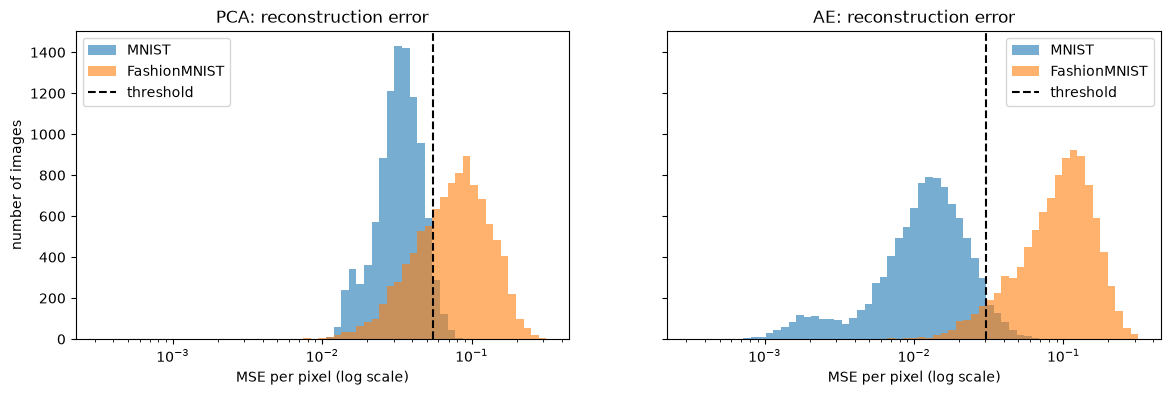

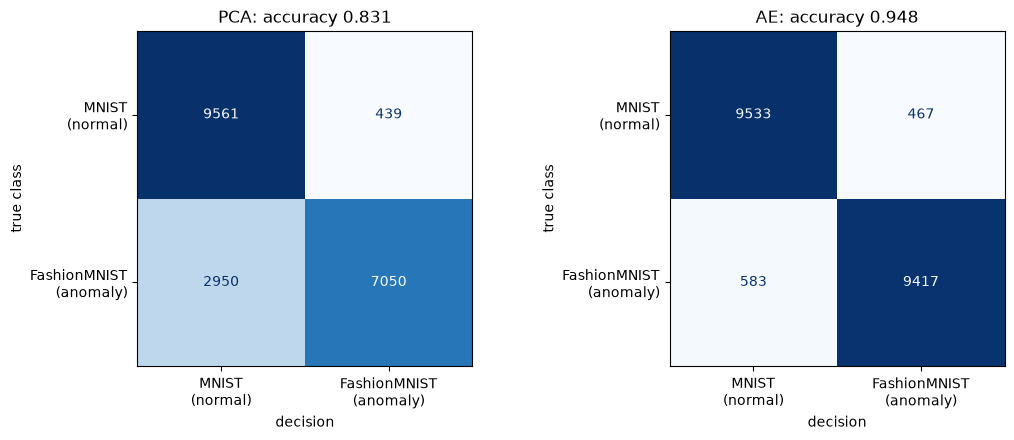

In [44]:
fashion_test = FashionMNIST("datasets", train=False, download=True, transform=transforms)
X_fashion, _ = to_arrays(fashion_test)

reconstruct = {
    "PCA": lambda X: pca.inverse_transform(pca.transform(X)),
    "AE": lambda X: ae_reconstruct(ae, X),
}
is_anomaly = np.r_[np.zeros(len(X_test)), np.ones(len(X_fashion))]

errors, thresholds, cms = {}, {}, {}
for name, rec in reconstruct.items():
    errors[name] = {"MNIST": mse_per_image(X_test, rec(X_test)),              # reconstruction error of every MNIST test image, (10000,)
                    "FashionMNIST": mse_per_image(X_fashion, rec(X_fashion))}   # reconstruction error of every FashionMNIST image, (10000,)
    
    score = np.r_[errors[name]["MNIST"], errors[name]["FashionMNIST"]]   # same order as is_anomaly
    
    thresholds[name] = np.percentile(mse_per_image(X_val, rec(X_val)), 95)   # 95th percentile of the reconstruction errors of X_val
    is_predicted_anomaly = score > thresholds[name]   # True where the score is above the threshold
    cms[name] = confusion_matrix(is_anomaly, is_predicted_anomaly)   # confusion matrix of is_anomaly vs is_predicted_anomaly, (2, 2)
    
    results[name]["anomaly acc."] = np.trace(cms[name]) / cms[name].sum()   # fraction of correct decisions (the diagonal)
    print(f"{name:<4} threshold {thresholds[name]:.4f}   accuracy MNIST vs FashionMNIST: {results[name]['anomaly acc.']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
bins = np.logspace(-3.5, -0.5, 60)
for ax, name in zip(axes, reconstruct):
    for data, values in errors[name].items():
        ax.hist(values, bins=bins, alpha=0.6, label=data)
    ax.axvline(thresholds[name], color="black", linestyle="--", label="threshold")
    ax.set_xscale("log")
    ax.set_title(f"{name}: reconstruction error")
    ax.set_xlabel("MSE per pixel (log scale)")
    ax.legend()
axes[0].set_ylabel("number of images")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, reconstruct):
    ConfusionMatrixDisplay(cms[name], display_labels=["MNIST\n(normal)", "FashionMNIST\n(anomaly)"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}: accuracy {results[name]['anomaly acc.']:.3f}")
    ax.set_xlabel("decision")
    ax.set_ylabel("true class")
plt.tight_layout()
plt.show()

With PCA the two histograms overlap a lot: a linear model with 10 components rebuilds clothes almost as badly (or as well) as digits. The AE is good at digits and only at digits, so the two distributions are far apart.

The confusion matrices tell the same story. The threshold was chosen so that both methods raise about the same number of false alarms (top-right cell, around 5% of the digits), so the difference is all in the bottom row: PCA accepts almost 3 clothes out of 10 as digits, the AE fewer than 1 in 15.

Here is what the AE does with clothes:

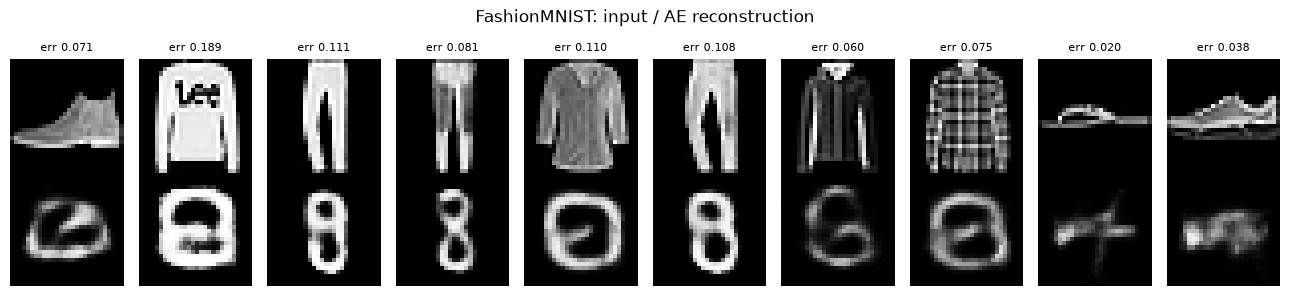

In [45]:
plot_images(np.concatenate([X_fashion[:10], ae_reconstruct(ae, X_fashion[:10])]),
            titles=[f"err {e:.3f}" for e in errors["AE"]["FashionMNIST"][:10]] + [""] * 10,
            suptitle="FashionMNIST: input / AE reconstruction")

It draws everything as a digit: a pullover becomes a 0 or an 8, a pair of trousers a thin 1 or 8.

The same score also finds the strangest images **inside** MNIST, which is a cheap way to look for odd or mislabelled samples in a dataset:

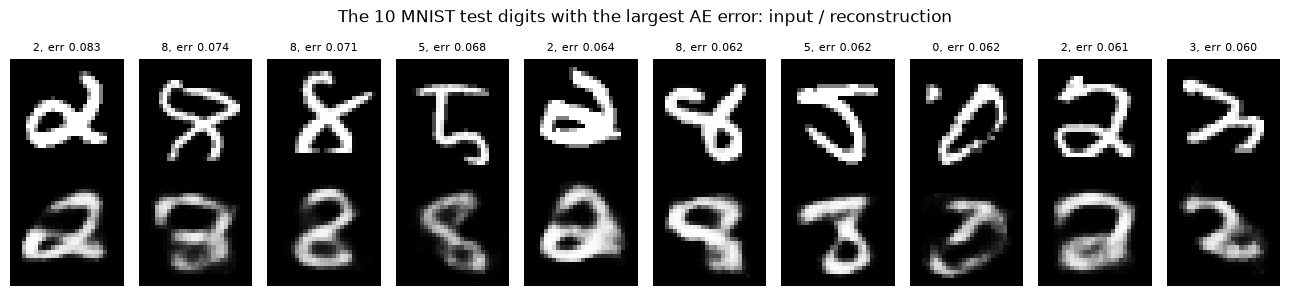

In [46]:
worst = errors["AE"]["MNIST"].argsort()[::-1][:10]
plot_images(np.concatenate([X_test[worst], ae_reconstruct(ae, X_test[worst])]),
            titles=[f"{y_test[i]}, err {errors['AE']['MNIST'][i]:.3f}" for i in worst] + [""] * 10,
            suptitle="The 10 MNIST test digits with the largest AE error: input / reconstruction")

One caveat: the reconstruction error is popular and simple, but not foolproof. An AE can rebuild some simple inputs it has never seen (an almost empty image, for example) and give them a low score.

## 3.3 Classification with few labels

The last task is the one that makes unsupervised learning so important in practice. Suppose we have all 48k training images but can only afford to label a handful per digit: 1, 10 or 100.

The standard way to test a representation in this setting is a **linear probe**: keep the representation frozen and train only a linear classifier (logistic regression) on top of it. If a linear model can read the digit from the codes, the information is there and easy to access.

With so few labels the result depends a lot on *which* images get labelled, so we repeat every experiment with 5 random choices and report mean and standard deviation.

### Exercise 9: linear probe

1. Complete `pick_labelled(n_per_class, seed)`. It simulates the labelling budget: it returns the indices of the training images whose label we are allowed to use. For every digit from 0 to 9:
   - find the indices of all the training images of that digit, `np.where(y_train == digit)[0]`;
   - choose `n_per_class` of them at random, without repetitions, with `rng.choice(candidates, n_per_class, replace=False)`.

   At the end, join the 10 arrays with `np.concatenate`: the result has `10 * n_per_class` indices. The generator `rng` has a fixed seed, so the choice is reproducible. The `assert` after the function checks that every digit gets exactly `n_per_class` images.
2. Complete `linear_probe(Z_train, Z_test, labelled)`: fit `LogisticRegression(max_iter=2000)` on the labelled codes only, `Z_train[labelled]`, with their labels `y_train[labelled]`. Return its accuracy on the whole test set, `clf.score(Z_test, y_test)`.

The rest of the cell runs the probe on the three representations with 1, 10 and 100 labels per digit, 5 random choices each, and plots the results.

   10 labels   pixels 0.439 ± 0.034
   10 labels   PCA    0.443 ± 0.032
   10 labels   AE     0.520 ± 0.043

  100 labels   pixels 0.748 ± 0.016
  100 labels   PCA    0.698 ± 0.014
  100 labels   AE     0.793 ± 0.029

 1000 labels   pixels 0.874 ± 0.005
 1000 labels   PCA    0.794 ± 0.003
 1000 labels   AE     0.891 ± 0.001



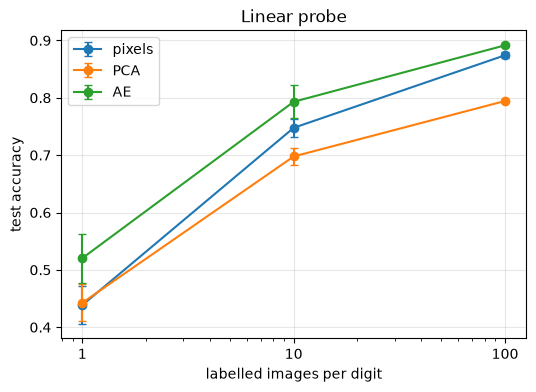

In [47]:
def pick_labelled(n_per_class, seed):
    # Indices of n_per_class random training images for every digit.
    rng = np.random.default_rng(seed)
    chosen = []
    for digit in range(10):
        candidates = np.where(y_train == digit)[0]   # indices of all the training images of this digit
        chosen.append(rng.choice(candidates, n_per_class, replace=False))   # n_per_class of them, at random, without replacement
    return np.concatenate(chosen)      # one array with all the chosen indices, shape (10 * n_per_class,)


idx = pick_labelled(3, seed=0)
assert idx.shape == (30,) and np.all(np.bincount(y_train[idx], minlength=10) == 3)


def linear_probe(Z_train, Z_test, labelled):
    clf = LogisticRegression(max_iter=2000).fit(Z_train[labelled], y_train[labelled])   # LogisticRegression(max_iter=2000) fitted on the labelled codes and labels
    return clf.score(Z_test, y_test)   # accuracy on the whole test set


N_PER_CLASS = [1, 10, 100] # n per class is the multiplication factor so we'll end up with n_per_class * 10 images
probe = {name: {} for name in reps}
for n in N_PER_CLASS:
    for name, (Z_train, Z_test) in reps.items(): # here we are itration MNIST, FASHIONMNIST, noise
        accs = [linear_probe(Z_train, Z_test, pick_labelled(n, seed)) for seed in range(5)]
        probe[name][n] = (np.mean(accs), np.std(accs))
        print(f"{10 * n:>5} labels   {name:<6} {np.mean(accs):.3f} ± {np.std(accs):.3f}")
    print()
for name in reps:
    results[name]["linear probe (10/digit)"] = probe[name][10][0]

fig, ax = plt.subplots(figsize=(6, 4))
for name in reps:
    means, stds = zip(*(probe[name][n] for n in N_PER_CLASS))
    ax.errorbar(N_PER_CLASS, means, yerr=stds, marker="o", capsize=3, label=name)
ax.set_xscale("log")
ax.set_xticks(N_PER_CLASS, [str(n) for n in N_PER_CLASS])
ax.set_xlabel("labelled images per digit")
ax.set_ylabel("test accuracy")
ax.set_title("Linear probe")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

With few labels the AE codes give the best classifier, and the gap is largest exactly where labels are scarcest. The unlabelled images did most of the work: the AE already separated the digits, and the labels only have to name the groups. With 100 labels per digit the pixels catch up, since a linear model on 784 features can learn a lot from 1000 examples; PCA with 10 components stays behind, because what it kept is not what distinguishes digits.

### Pre-training and fine-tuning

The linear probe keeps the encoder frozen. In deep learning we usually go one step further and **fine-tune**: we put a linear head on top of the pre-trained encoder and keep training *all* the weights with the few labels. We compare it with the same network trained from random weights.

| | from scratch | pre-trained |
|---|---|---|
| encoder at the start | random weights | the weights of the AE encoder |
| data seen before | none | 48k images, no labels |
| training | the few labelled images | the same images |

This is the recipe behind most modern models: pre-train on a lot of unlabelled data, then fine-tune on the small labelled dataset of the task you care about.

### Exercise 10: from scratch vs pre-trained

`Classifier` (an encoder followed by a `Linear(latent_dim, 10)` head) and `train_classifier` (train it on the labelled images and return the test accuracy) are given. In the loop at the end of the cell, for every seed, build the two encoders that are passed to `train_classifier`:

- `scratch_encoder`: the `.encoder` of a **new** `AutoEncoder(LATENT_DIM)`;
- `pretrained_encoder`: a copy of `ae.encoder`, made with `copy.deepcopy`. Without the copy, fine-tuning would change `ae` itself, and the next seed would start from an already fine-tuned encoder.

The cell trains 12 small classifiers and takes a minute or two.

In [48]:
class Classifier(torch.nn.Module):
    def __init__(self, encoder, latent_dim, n_classes=10):
        super().__init__()
        self.encoder = encoder
        self.head = torch.nn.Linear(latent_dim, n_classes)

    def forward(self, x):
        return self.head(self.encoder(x.reshape(x.shape[0], -1)))


def accuracy(model, dataloader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in dataloader:
            correct += (model(x.to(DEVICE)).argmax(dim=1).cpu() == y).sum().item()
    return correct / len(dataloader.dataset)


def train_classifier(encoder, labelled, epochs=100):
    # Train encoder + linear head on the labelled training images, return the test accuracy.
    torch.manual_seed(0)
    model = Classifier(encoder, LATENT_DIM).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = make_loader(X_train[labelled], y_train[labelled], batch_size=32, shuffle=True)
    for _ in range(epochs):
        model.train()
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return accuracy(model, test_loader)


for n in [10, 100]:
    acc_scratch, acc_pretrained = [], []
    for seed in range(3):
        labelled = pick_labelled(n, seed)
        scratch_encoder = AutoEncoder(LATENT_DIM).encoder   # the .encoder of a new AutoEncoder(LATENT_DIM): random weights
        pretrained_encoder = copy.deepcopy(ae.encoder)   # a deep copy of ae.encoder: the weights learned without labels
        acc_scratch.append(train_classifier(scratch_encoder, labelled))
        acc_pretrained.append(train_classifier(pretrained_encoder, labelled))
    print(f"{10 * n:>5} labels   from scratch {np.mean(acc_scratch):.3f} ± {np.std(acc_scratch):.3f}"
          f"   pre-trained {np.mean(acc_pretrained):.3f} ± {np.std(acc_pretrained):.3f}")

  100 labels   from scratch 0.674 ± 0.021   pre-trained 0.745 ± 0.007
 1000 labels   from scratch 0.901 ± 0.004   pre-trained 0.923 ± 0.000


Starting from the pre-trained encoder gives a clearly better classifier than starting from random weights, and the gain is largest when labels are fewest. (For reference, with all 48k labels an MLP trained from scratch reaches about 97%, as we saw in Lab 1.)

Compare these numbers with the linear probe. With 10 labels per digit, fine-tuning the whole encoder is *worse* than simply training a linear layer on the frozen codes: updating more than half a million weights with 100 images overfits and partly destroys what the encoder learned. With 100 labels per digit fine-tuning wins. Freezing or fine-tuning is a choice that depends on how many labels you have.

# Summary

All the scores of Part 3 in one table (higher is better everywhere):

In [49]:
tasks = ["clustering acc.", "anomaly acc.", "linear probe (10/digit)"]
print(f"{'task':<32}" + "".join(f"{name:>10}" for name in reps))
for task in tasks:
    row = "".join(f"{results[name][task]:>10.3f}" if task in results[name] else f"{'-':>10}" for name in reps)
    print(f"{task:<32}{row}")
print(f"{'size of the representation':<32}" + "".join(f"{reps[name][0].shape[1]:>10}" for name in reps))

task                                pixels       PCA        AE
clustering acc.                      0.585     0.580     0.692
anomaly acc.                             -     0.831     0.948
linear probe (10/digit)              0.748     0.698     0.793
size of the representation             784        10        10


- A **representation** is a map from the raw input to a vector. Its quality is best judged by how useful it is for tasks it was not trained for.
- **PCA** gives a compact representation for free, but it is linear and keeps the directions of largest variance, which are not necessarily the ones that matter.
- An **autoencoder** learns a non-linear representation from unlabelled data with a self-supervised task: rebuild the input through a bottleneck.
- With the same 10 numbers, the AE codes beat the PCA codes on every task, and match or beat the 784 raw pixels: clusters are cleaner, anomalies stand out, and a few labels are enough to train a classifier.
- Unsupervised pre-training pays off most when unlabelled data is abundant and labels are scarce, which is the usual situation in practice.

**The take-home message: representations are useful.** The AE was trained only to rebuild its input, yet its codes made clustering, anomaly detection and classification easier with the same simple tools. Most of the work of a deep network is building a good representation; once you have one, many tasks become easy.

# Homework

## 1. Is a better reconstruction a better representation?

Train an `AutoEncoder` with `latent_dim` in `[2, 5, 10, 20, 50]` (and fit PCA with the same number of components). For each size, measure:

1. the test reconstruction error;
2. the clustering accuracy of K-means on the codes;
3. the linear probe accuracy with 10 labels per digit.

Plot the three quantities as a function of `latent_dim`, for the AE and for PCA.

- Does the reconstruction always improve with a larger bottleneck? And the downstream tasks?
- What does this tell you about using the reconstruction error to choose the size of the bottleneck?

## 2. A linear autoencoder is PCA

Remove all the ReLUs and the sigmoid from the `AutoEncoder` (only `Linear` layers) and train it with `latent_dim=2`.

- Compare its test reconstruction error with the one of PCA with 2 components. What do you notice?
- Plot its latent space next to the one of PCA. Are they the same? (Hint: they span the same plane, but the axes may be rotated and scaled.)

# Homework solutions

## 1. Is a better reconstruction a better representation?

For every size we train a new AE (same setup as in the lab) and fit a PCA. This takes a few minutes.

latent_dim  2   AE: 0.038, 0.541, 0.642   PCA: 0.056, 0.408, 0.420
latent_dim  5   AE: 0.023, 0.714, 0.822   PCA: 0.045, 0.500, 0.604
latent_dim 10   AE: 0.014, 0.692, 0.793   PCA: 0.034, 0.580, 0.698
latent_dim 20   AE: 0.008, 0.626, 0.767   PCA: 0.024, 0.588, 0.738
latent_dim 50   AE: 0.007, 0.570, 0.762   PCA: 0.011, 0.594, 0.744


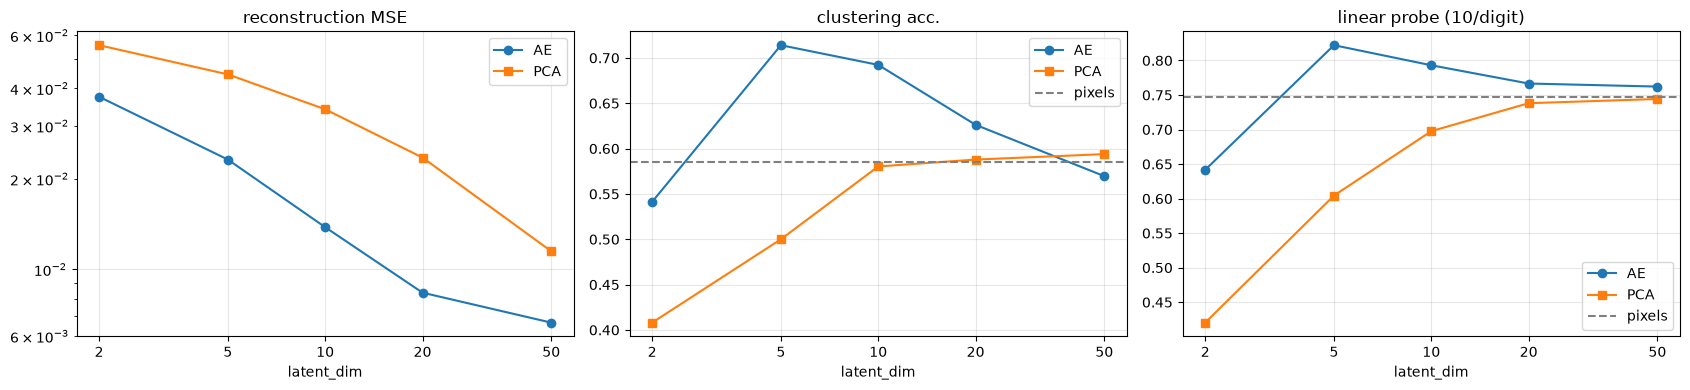

In [50]:
LATENT_DIMS = [2, 5, 10, 20, 50]
hw = {"AE": {}, "PCA": {}}

for d in LATENT_DIMS:
    torch.manual_seed(0)
    model = AutoEncoder(d).to(DEVICE)
    train_autoencoder(model, epochs=10, verbose=False)
    pca_d = PCA(n_components=d).fit(X_train)
    encoders = {
        "AE": (lambda X: get_codes(model, X), lambda X: ae_reconstruct(model, X)),
        "PCA": (pca_d.transform, lambda X: pca_d.inverse_transform(pca_d.transform(X))),
    }
    for name, (encode, rec) in encoders.items():
        Z_train, Z_test = encode(X_train), encode(X_test)
        km = KMeans(n_clusters=10, n_init=5, random_state=0).fit(Z_train)
        hw[name][d] = {
            "reconstruction MSE": mse_per_image(X_test, rec(X_test)).mean(),
            "clustering acc.": cluster_accuracy(y_test, km.predict(Z_test)),
            "linear probe (10/digit)": np.mean([linear_probe(Z_train, Z_test, pick_labelled(10, s)) for s in range(5)]),
        }
    print(f"latent_dim {d:>2}   " + "   ".join(
        f"{name}: " + ", ".join(f"{v:.3f}" for v in hw[name][d].values()) for name in hw))

metrics = list(hw["AE"][LATENT_DIMS[0]])
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, metric in zip(axes, metrics):
    for name, marker in [("AE", "o"), ("PCA", "s")]:
        ax.plot(LATENT_DIMS, [hw[name][d][metric] for d in LATENT_DIMS], marker=marker, label=name)
    ax.set_xscale("log")
    ax.set_xticks(LATENT_DIMS, [str(d) for d in LATENT_DIMS])
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel("latent_dim")
    ax.set_title(metric)
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_yscale("log")
axes[1].axhline(results["pixels"]["clustering acc."], color="gray", linestyle="--", label="pixels")
axes[2].axhline(results["pixels"]["linear probe (10/digit)"], color="gray", linestyle="--", label="pixels")
axes[1].legend()
axes[2].legend()
plt.tight_layout()
plt.show()

**Reconstruction.** It always improves: the test error decreases steadily with the size of the bottleneck, for both methods (AE from about 0.038 with 2 numbers to 0.007 with 50, PCA from 0.056 to 0.011). For PCA this is guaranteed, since adding a component can only help; for the AE it holds in practice, with diminishing returns after 20.

**Downstream tasks.** They do not. For the AE both clustering and the linear probe peak at a small bottleneck (5 numbers: about 0.71 clustering accuracy and 0.82 probe accuracy) and then get worse. With 50 numbers K-means on the AE codes is even below K-means on the raw pixels. A narrow bottleneck forces the AE to keep only the most important factor, which digit it is, so images of the same digit end up close. A wide bottleneck also stores style details (thickness, slant, small strokes), and these dominate the Euclidean distances. PCA instead improves slowly and approaches the pixels: with many components it preserves the pixel distances, nothing more. At every size the AE still beats PCA on the probe.

**Consequence.** The reconstruction error keeps decreasing as the bottleneck grows, so it cannot tell you which size gives the most useful representation: it would always pick the largest one. Reconstruction is only a proxy task. To choose the bottleneck, or to compare representations in general, you have to measure them on the tasks you care about, ideally on a validation set.

## 2. A linear autoencoder is PCA

`LinearAutoEncoder` inherits `encode`, `decode` and `forward` from `AutoEncoder` and only replaces the two `Sequential`s, without activations. A stack of linear layers is a single linear map, so the decoder output lives in a 2D plane of the pixel space, and the best such plane for the MSE is the PCA plane.

In [51]:
class LinearAutoEncoder(AutoEncoder):
    def __init__(self, latent_dim):
        super().__init__(latent_dim)
        self.encoder = torch.nn.Sequential(torch.nn.Linear(784, 512), torch.nn.Linear(512, 256),
                                           torch.nn.Linear(256, latent_dim))
        self.decoder = torch.nn.Sequential(torch.nn.Linear(latent_dim, 256), torch.nn.Linear(256, 512),
                                           torch.nn.Linear(512, 784))


torch.manual_seed(0)
linear_ae = LinearAutoEncoder(latent_dim=2).to(DEVICE)
train_autoencoder(linear_ae, epochs=10, verbose=False)
linear_ae_mse = evaluate_unsupervised(linear_ae, test_loader)
print(f"test MSE   PCA (2): {pca_2_mse:.4f}   linear AE (2): {linear_ae_mse:.4f}   AE (2): {ae_2_mse:.4f}")

test MSE   PCA (2): 0.0557   linear AE (2): 0.0559   AE (2): 0.0374


To check that the two latent spaces carry the same information, we fit the best affine map from the linear-AE codes to the PCA codes (least squares) and measure the angles between the plane spanned by the decoder and the PCA plane.

R^2 of the affine map linear-AE codes -> PCA codes: 0.9987
angles between the decoder plane and the PCA plane (degrees): [4.78 2.97]


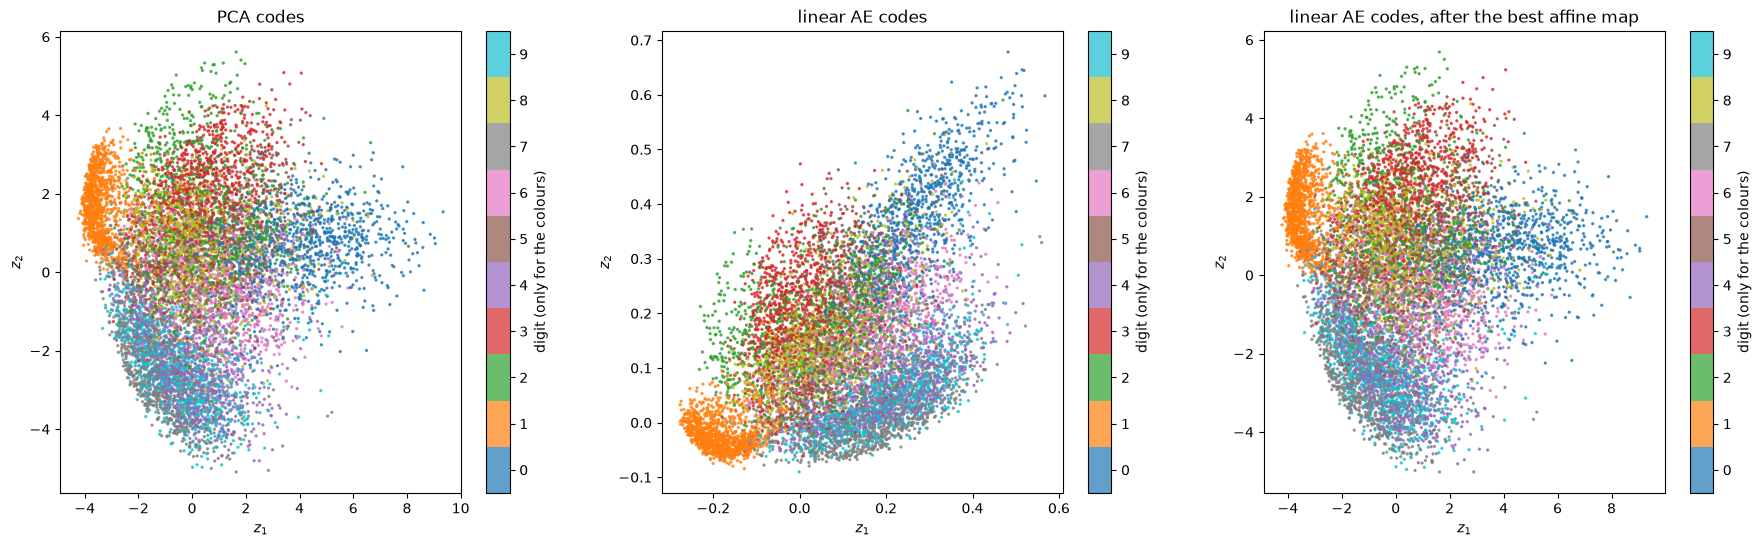

In [52]:
from scipy.linalg import subspace_angles

lin_z = get_codes(linear_ae, X_test)
Z1 = np.hstack([lin_z, np.ones((len(lin_z), 1))])
M, *_ = np.linalg.lstsq(Z1, pca_2_z, rcond=None)
pca_from_lin = Z1 @ M
r2 = 1 - ((pca_2_z - pca_from_lin) ** 2).sum() / ((pca_2_z - pca_2_z.mean(axis=0)) ** 2).sum()
print(f"R^2 of the affine map linear-AE codes -> PCA codes: {r2:.4f}")

with torch.no_grad():
    B = (linear_ae.decoder[2].weight @ linear_ae.decoder[1].weight @ linear_ae.decoder[0].weight).cpu().numpy()
print("angles between the decoder plane and the PCA plane (degrees):",
      np.round(np.degrees(subspace_angles(B, pca_2.components_.T)), 2))

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
plot_latent_space(pca_2_z, y_test, title="PCA codes", ax=axes[0])
plot_latent_space(lin_z, y_test, title="linear AE codes", ax=axes[1])
plot_latent_space(pca_from_lin, y_test, title="linear AE codes, after the best affine map", ax=axes[2])
plt.show()

**Reconstruction error.** The linear AE reaches almost exactly the error of PCA with 2 components (0.0559 against 0.0557) and cannot do better: PCA is the optimal linear encoder/decoder for the MSE, so the best a linear AE can do is to find the same solution. The non-linear AE (0.037) is much better than both, and the improvement comes from the non-linearities, not from the extra layers.

**Latent spaces.** The scatter plots look different (rotated, scaled, possibly reflected, not centred), but they carry the same information: an affine map turns the linear-AE codes into the PCA codes almost perfectly ($R^2 \approx 0.999$), and the plane spanned by the decoder is the PCA plane up to a few degrees, due to incomplete optimisation. PCA picks a specific basis of that plane, orthonormal and ordered by explained variance. The AE can learn any basis of the same plane, because the loss does not change if $z$ is multiplied by an invertible matrix and the decoder by its inverse. This is also a reminder that the individual coordinates of a learned code usually have no meaning on their own: only the geometry does.